# DOE-026
## クロス直後、含み益が伸びない場合に許容できる含み損カウント

- 対象銘柄: 9984
- 実験パラメータ
    - COUNT_NEGATIVE_MIN
        - 2, 4, 6, 8, 10, 12, 14, 16, 18, 20
- 固定パラメータ
    - TYPE_MA_1
        - EMA
    - PERIOD_MA_1
        - 90
    - PERIOD_MA_2（長周期移動平均線）
        - 1350
    - LOSSCUT_SIMPLE（単純ロスカット）
        - -50
- MA1 / MA2 クロス・シグナルのエントリ・エグジット
- 評価指標
    - 収益と約定回数

In [1]:
from pathlib import Path

import pandas as pd

# === 実験番号 ===
name_doe = "doe-026"

# pd.set_option("display.max_rows", None)
pd.set_option("display.max_columns", None)
pd.set_option("display.width", 300)

# 指定したディレクトリのPathオブジェクトを作成
dir_path = Path(f"../doe/{name_doe}")

# .glob() で .csv ファイルのリスト（イテレータ）を取得してリストに変換
list_csv_file = sorted([str(p) for p in dir_path.glob("*.csv") if p.is_file()])

# 集計対象の条件列
columns_group = [
    "TYPE_MA_1",
    "COUNT_NEGATIVE_MIN",
]

# CSV ファイルを読み込んで結合
df = pd.concat(
    [pd.read_csv(file) for file in list_csv_file],
    ignore_index=True,
)

# 条件ごとに Profit を集計
df_total = df.groupby(columns_group, as_index=False).agg(
    Profit_Total=("Profit", "sum"),
    Profit_Median=("Profit", "median"),
    Transactions_Median=("Transactions", "median"),
)

print(df_total)
print("\n *** Past", len(list_csv_file), "days statistics ***")
print("\n△ Profit_Total Top 3")
print(df_total.nlargest(3, "Profit_Total"))
print("\n▼ Profit_Total Bottom 3")
print(df_total.nsmallest(3, "Profit_Total"))
print("\n\n△ Profit_Median Top 3")
print(df_total.nlargest(3, "Profit_Median"))
print("\n▼ Profit_Median Bottom 3")
print(df_total.nsmallest(3, "Profit_Median"))

   TYPE_MA_1  COUNT_NEGATIVE_MIN  Profit_Total  Profit_Median  Transactions_Median
0        EMA                   0        -729.0          -24.0                 18.0
1        EMA                   2        -997.0          -48.0                 32.0
2        EMA                   4       -1466.0          -59.0                 32.0
3        EMA                   6       -1463.0          -61.0                 32.0
4        EMA                   8       -1504.0          -66.0                 30.0
5        EMA                  10       -1593.0          -57.0                 30.0
6        EMA                  12       -1626.0          -59.0                 30.0
7        EMA                  14       -1337.0          -58.0                 28.0
8        EMA                  16       -1124.0          -48.0                 28.0
9        EMA                  18       -1217.0          -50.0                 28.0
10       EMA                  20       -1040.0          -55.0                 28.0

 **

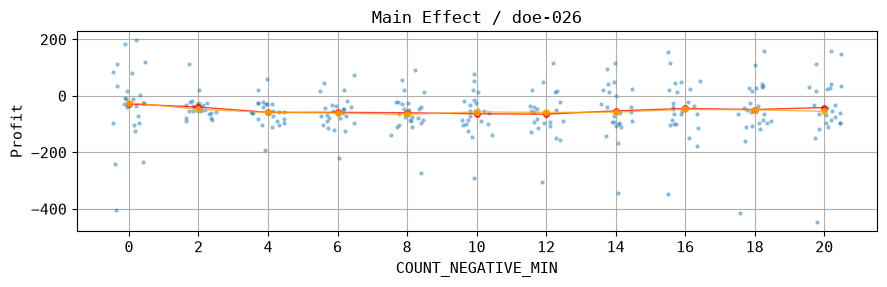

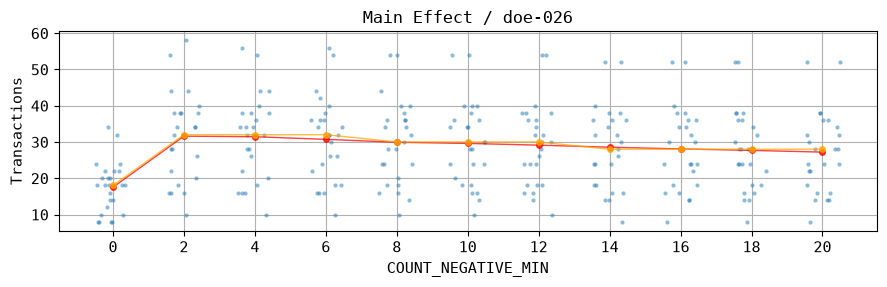

In [2]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.rcParams["font.family"] = "monospace"
plt.rcParams["font.size"] = 11

cols_param = [
    "COUNT_NEGATIVE_MIN",
]


for name_y in ["Profit", "Transactions"]:
    fig, ax = plt.subplots(1, 1, figsize=(9, 3))

    #for ax, col in zip(axes.flatten(), cols_param):
    col = cols_param[0]
    sns.stripplot(
        data=df,
        x=col,
        y=name_y,
        ax=ax,
        size=3,
        jitter=0.25,  # 横方向へのばらつき具合
        alpha=0.5,  # 重なりが見やすいよう少し透明に
        color="tab:blue",  # 散布図の色を指定
    )

    # x の各水準ごとの平均値
    mean = df.groupby(col)[name_y].mean()
    # stripplot の x 軸位置（0, 1, 2...）に合わせて線をつなぐ
    ax.plot(
        range(len(mean)),
        mean.values,
        "o-",
        color="red",
        markersize=4,
        linewidth=1,
        alpha=0.75,
        zorder=5,  # 点の裏に隠れないよう前面に描画
    )

    # x の各水準ごとのメジアン
    median = df.groupby(col)[name_y].median()
    # stripplot の x 軸位置（0, 1, 2...）に合わせて線をつなぐ
    ax.plot(
        range(len(median)),
        median.values,
        "o-",
        color="orange",
        markersize=4,
        linewidth=1,
        alpha=0.75,
        zorder=5,
    )

    ax.set(xlabel=col, ylabel=name_y)
    ax.grid(True)

    ax.set_title(f"Main Effect / {name_doe}", fontsize=12)
    #fig.suptitle(f"Main Effect / {name_doe}", fontsize=9)

    plt.tight_layout()
    pngfile = f"../doe/{name_doe}/main_effect_{name_y}.png"
    plt.savefig(pngfile)
    plt.show()